# UNSW-NB15 — Exploratory Data Analysis

**Project:** Machine Learning-Based Network Intrusion Detection and Analytics System  
**Dataset:** UNSW-NB15 (official predefined train/test split)  
**Phase:** 2 — Exploratory Data Analysis  

## Purpose

This notebook explores the raw UNSW-NB15 data to understand its structure, class balance,
feature distributions, and data-quality characteristics **before any preprocessing or modelling**.
No transformations are applied; the CSVs are loaded and examined read-only.

## Outputs

| Type | Location |
|---|---|
| Charts (PNG) | `results/figures/` |
| EDA summary (JSON) | `results/metrics/eda_summary.json` |

## How to run

```
# From the project root
.venv\Scripts\jupyter.exe lab notebooks/01_exploratory_data_analysis.ipynb
```

Or run top-to-bottom with nbconvert:
```
.venv\Scripts\jupyter.exe nbconvert --to notebook --execute notebooks/01_exploratory_data_analysis.ipynb
```

## 0. Imports and configuration

In [1]:
import sys
import logging
from pathlib import Path

import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.ticker

# Ensure project root is on the path when running from notebooks/
PROJECT_ROOT = Path().resolve().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.data_loader import load_train, load_test, validate_schema
from src.eda import (
    dataset_overview,
    class_distribution,
    check_duplicates,
    check_id_column,
    numeric_summary,
    categorical_summary,
    attack_category_summary,
    plot_class_distribution,
    plot_numeric_distributions,
    plot_categorical_frequencies,
    plot_correlation_heatmap,
    plot_attack_category_distribution,
    save_eda_summary,
)

logging.basicConfig(level=logging.INFO, format='%(levelname)s: %(message)s')

# Output directories (relative to project root)
FIGURES_DIR = PROJECT_ROOT / 'results' / 'figures'
METRICS_DIR = PROJECT_ROOT / 'results' / 'metrics'
DATA_DIR    = PROJECT_ROOT / 'data'

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
METRICS_DIR.mkdir(parents=True, exist_ok=True)

print(f'Python:         {sys.version}')
print(f'pandas:         {pd.__version__}')
print(f'matplotlib:     {matplotlib.__version__}')
print(f'Project root:   {PROJECT_ROOT}')
print(f'Figures dir:    {FIGURES_DIR}')
print(f'Metrics dir:    {METRICS_DIR}')

Python:         3.13.0 (tags/v3.13.0:60403a5, Oct  7 2024, 09:38:07) [MSC v.1941 64 bit (AMD64)]
pandas:         3.0.6
matplotlib:     3.11.2
Project root:   C:\Users\meema\ML_Network_Intrusion_Detection
Figures dir:    C:\Users\meema\ML_Network_Intrusion_Detection\results\figures
Metrics dir:    C:\Users\meema\ML_Network_Intrusion_Detection\results\metrics


## 1. Load data and validate schema

`load_train` / `load_test` read the CSV and strip column-name whitespace.  
`validate_schema` checks that `label` ∈ {0,1}, `attack_cat` is present,
and that no attack row has NaN in `attack_cat`.

In [2]:
train_df = load_train(DATA_DIR)
test_df  = load_test(DATA_DIR)

train_schema = validate_schema(train_df, 'train')
test_schema  = validate_schema(test_df,  'test')

print('Train: %d rows × %d columns' % (len(train_df), len(train_df.columns)))
print('Test:  %d rows × %d columns' % (len(test_df),  len(test_df.columns)))
print('\nTrain label distribution:', train_schema['label_distribution'])
print('Test  label distribution:', test_schema['label_distribution'])
print('\nIdentifier candidates found:', train_schema['identifier_candidates_found'])

INFO: Loading train split from: C:\Users\meema\ML_Network_Intrusion_Detection\data\UNSW_NB15_training-set.csv


INFO: train split loaded: 175341 rows, 45 columns


INFO: Loading test split from: C:\Users\meema\ML_Network_Intrusion_Detection\data\UNSW_NB15_testing-set.csv


INFO: test split loaded: 82332 rows, 45 columns


INFO: [train] rows=175341, columns=45


...

INFO: [test] rows=82332, columns=45


INFO: [test] label distribution: {1: 45332, 0: 37000}


INFO: [test] columns with missing values: none


INFO: [test] Candidate identifier/address columns found (Phase-3 review required before including as features): ['id']


Train: 175341 rows × 45 columns
Test:  82332 rows × 45 columns

Train label distribution: {1: 119341, 0: 56000}
Test  label distribution: {1: 45332, 0: 37000}

Identifier candidates found: ['id']


## 2. Dataset dimensions, column types, and descriptive overview

In [3]:
train_overview = dataset_overview(train_df, 'train')
test_overview  = dataset_overview(test_df,  'test')

print('=== TRAIN ===')
print(f"  Rows:              {train_overview['rows']:>10,}")
print(f"  Columns:           {train_overview['columns']:>10}")
print(f"  Numeric columns:   {len(train_overview['numeric_cols']):>10}")
print(f"  Categorical cols:  {len(train_overview['categorical_cols']):>10}")
print(f"  Total missing:     {train_overview['missing_total']:>10,}")
print()
print('=== TEST ===')
print(f"  Rows:              {test_overview['rows']:>10,}")
print(f"  Columns:           {test_overview['columns']:>10}")
print(f"  Numeric columns:   {len(test_overview['numeric_cols']):>10}")
print(f"  Categorical cols:  {len(test_overview['categorical_cols']):>10}")
print(f"  Total missing:     {test_overview['missing_total']:>10,}")
print()
print('Column names:', train_overview['column_names'])

INFO: [train] 175341 rows × 45 cols | missing total: 0


INFO: [test] 82332 rows × 45 cols | missing total: 0


=== TRAIN ===
  Rows:                 175,341
  Columns:                   45
  Numeric columns:           41
  Categorical cols:           4
  Total missing:              0

=== TEST ===
  Rows:                  82,332
  Columns:                   45
  Numeric columns:           41
  Categorical cols:           4
  Total missing:              0

Column names: ['id', 'dur', 'proto', 'service', 'state', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports', 'attack_cat', 'label']


In [4]:
# Data-type table for quick reference
dtype_df = pd.DataFrame({
    'column': list(train_overview['dtypes'].keys()),
    'dtype':  list(train_overview['dtypes'].values()),
})
print(dtype_df.to_string(index=False))

           column   dtype
               id   int64
              dur float64
            proto     str
          service     str
            state     str
            spkts   int64
            dpkts   int64
           sbytes   int64
           dbytes   int64
             rate float64
             sttl   int64
             dttl   int64
            sload float64
            dload float64
            sloss   int64
            dloss   int64
           sinpkt float64
           dinpkt float64
             sjit float64
             djit float64
             swin   int64
            stcpb   int64
            dtcpb   int64
             dwin   int64
           tcprtt float64
           synack float64
           ackdat float64
            smean   int64
            dmean   int64
      trans_depth   int64
response_body_len   int64
       ct_srv_src   int64
     ct_state_ttl   int64
       ct_dst_ltm   int64
 ct_src_dport_ltm   int64
 ct_dst_sport_ltm   int64
   ct_dst_src_ltm   int64
     is_ftp_

## 3. Class distribution — normal vs attack

The binary target column `label` encodes:
- **0 = Normal** — benign network traffic  
- **1 = Attack** — one of nine attack categories

Class balance directly affects which evaluation metrics matter most.
A classifier that predicts "attack" for every row would score 68% accuracy
on the training set — high accuracy alone is therefore not a useful metric.

In [5]:
train_dist = class_distribution(train_df, 'train')
test_dist  = class_distribution(test_df,  'test')

print('TRAIN split')
print(f"  Normal (0):  {train_dist['normal_count']:>8,}  ({train_dist['normal_pct']:.1f}%)")
print(f"  Attack (1):  {train_dist['attack_count']:>8,}  ({train_dist['attack_pct']:.1f}%)")
print(f"  Total:       {train_dist['total']:>8,}")
print()
print('TEST split')
print(f"  Normal (0):  {test_dist['normal_count']:>8,}  ({test_dist['normal_pct']:.1f}%)")
print(f"  Attack (1):  {test_dist['attack_count']:>8,}  ({test_dist['attack_pct']:.1f}%)")
print(f"  Total:       {test_dist['total']:>8,}")

INFO: [train] label distribution — normal: 56000 (31.9%), attack: 119341 (68.1%)


INFO: [test] label distribution — normal: 37000 (44.9%), attack: 45332 (55.1%)


TRAIN split
  Normal (0):    56,000  (31.9%)
  Attack (1):   119,341  (68.1%)
  Total:        175,341

TEST split
  Normal (0):    37,000  (44.9%)
  Attack (1):    45,332  (55.1%)
  Total:         82,332


In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

palette = {0: '#4393c3', 1: '#d6604d'}
for ax, (dist, split) in zip(axes, [(train_dist, 'Train'), (test_dist, 'Test')]):
    labels = ['Normal (0)', 'Attack (1)']
    counts = [dist['normal_count'], dist['attack_count']]
    pcts   = [dist['normal_pct'],   dist['attack_pct']]
    colors = [palette[0], palette[1]]
    bars = ax.bar(labels, counts, color=colors, edgecolor='white', linewidth=0.8)
    for bar, pct in zip(bars, pcts):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height() + max(counts) * 0.01,
            f'{pct:.1f}%', ha='center', va='bottom', fontsize=11,
        )
    ax.set_title(f'Class Distribution — {split} split', fontsize=12)
    ax.set_ylabel('Records')
    ax.yaxis.set_major_formatter(matplotlib.ticker.FuncFormatter(lambda x, _: f'{int(x):,}'))

fig.tight_layout()
fig_path = FIGURES_DIR / 'class_distribution_both_splits.png'
fig.savefig(fig_path, dpi=120, bbox_inches='tight')
plt.show()
print(f'Saved: {fig_path}')

Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\class_distribution_both_splits.png


C:\Users\meema\AppData\Local\Temp\ipykernel_11668\2919154024.py:23: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


**Observation:** Attacks outnumber normal traffic in both splits (~68% attack in training,
~55% in testing). This is an **inverted imbalance** compared to most real-world deployments
where normal traffic dominates. In evaluation, we will report per-class precision and recall
rather than relying on accuracy alone.

## 4. Missing values and duplicate rows

In [7]:
train_dups = check_duplicates(train_df, 'train')
test_dups  = check_duplicates(test_df,  'test')

print('TRAIN')
print(f"  Duplicate rows: {train_dups['duplicate_rows']}")
print(f"  Duplicate IDs:  {train_dups['duplicate_ids']}")
print()
print('TEST')
print(f"  Duplicate rows: {test_dups['duplicate_rows']}")
print(f"  Duplicate IDs:  {test_dups['duplicate_ids']}")
print()

# Missing values per column (both splits)
missing_train = {k: v for k, v in train_overview['missing_counts'].items() if v > 0}
missing_test  = {k: v for k, v in test_overview['missing_counts'].items() if v > 0}
print('Missing values in TRAIN (non-zero columns):', missing_train if missing_train else 'none')
print('Missing values in TEST  (non-zero columns):', missing_test  if missing_test  else 'none')

INFO: [train] duplicate rows: 0 | duplicate ids: 0


INFO: [test] duplicate rows: 0 | duplicate ids: 0


TRAIN
  Duplicate rows: 0
  Duplicate IDs:  0

TEST
  Duplicate rows: 0
  Duplicate IDs:  0

Missing values in TRAIN (non-zero columns): none
Missing values in TEST  (non-zero columns): none


## 5. Identifier column (`id`) analysis

The `id` column is a row-level sequential integer assigned during dataset construction.
This section confirms its properties and explains why it must not be used as a predictive feature.

In [8]:
id_info = check_id_column(train_df, test_df)

print('TRAIN id column')
print(f"  Range:   {id_info['train_id_min']} – {id_info['train_id_max']}")
print(f"  Unique:  {id_info['train_id_unique']:,}  (out of {len(train_df):,} rows)")
print()
print('TEST id column')
print(f"  Range:   {id_info['test_id_min']} – {id_info['test_id_max']}")
print(f"  Unique:  {id_info['test_id_unique']:,}  (out of {len(test_df):,} rows)")
print()
print(f"ID overlap between splits: {id_info['id_overlap_count']:,} IDs")
print()
print('Recommendation:')
print(id_info['recommendation'])

INFO: id overlap between train and test: 82332 IDs


TRAIN id column
  Range:   1 – 175341
  Unique:  175,341  (out of 175,341 rows)

TEST id column
  Range:   1 – 82332
  Unique:  82,332  (out of 82,332 rows)

ID overlap between splits: 82,332 IDs

Recommendation:
The 'id' column is a row-level identifier assigned during dataset construction.  It carries no network-flow information and its numeric range overlaps between train and test splits (both use 1-based sequential integers), so any correlation with 'label' would be a dataset artifact, not a real signal.  'id' must be excluded from all model feature sets.


**Key finding:** The `id` ranges in train (1–175,341) and test (1–82,332) overlap completely
because both use independent 1-based sequential integers. Any correlation between `id` and
`label` would be a dataset construction artifact. **`id` will be excluded from all model features.**

## 6. Numeric feature distributions

The 39 numeric features include byte counts, packet counts, timing values,
jitter, TTL, and connection-tracking counters.
Most are strongly right-skewed with extreme outliers — a characteristic pattern
in network traffic data.

In [9]:
# Define feature columns: numeric only, exclude id and label
NUMERIC_FEATURE_COLS = [
    c for c in train_df.select_dtypes(include='number').columns
    if c not in ('id', 'label')
]
CAT_FEATURE_COLS = ['proto', 'service', 'state']

print(f'Numeric feature columns ({len(NUMERIC_FEATURE_COLS)}): {NUMERIC_FEATURE_COLS}')
print(f'Categorical feature columns: {CAT_FEATURE_COLS}')

Numeric feature columns (39): ['dur', 'spkts', 'dpkts', 'sbytes', 'dbytes', 'rate', 'sttl', 'dttl', 'sload', 'dload', 'sloss', 'dloss', 'sinpkt', 'dinpkt', 'sjit', 'djit', 'swin', 'stcpb', 'dtcpb', 'dwin', 'tcprtt', 'synack', 'ackdat', 'smean', 'dmean', 'trans_depth', 'response_body_len', 'ct_srv_src', 'ct_state_ttl', 'ct_dst_ltm', 'ct_src_dport_ltm', 'ct_dst_sport_ltm', 'ct_dst_src_ltm', 'is_ftp_login', 'ct_ftp_cmd', 'ct_flw_http_mthd', 'ct_src_ltm', 'ct_srv_dst', 'is_sm_ips_ports']
Categorical feature columns: ['proto', 'service', 'state']


In [10]:
# Descriptive statistics table
stats = numeric_summary(train_df, NUMERIC_FEATURE_COLS)
print('Descriptive statistics (training split):')
display(stats.round(3))

Descriptive statistics (training split):


,count,mean,std,min,25%,50%,75%,99%,max
feature,,,,,,,,,
dur,175341.0,1.359000e+00,6.480000e+00,0.0,0.000,0.002,6.680000e-01,4.535300e+01,6.000000e+01
spkts,175341.0,2.029900e+01,1.368880e+02,1.0,2.000,2.000,1.200000e+01,2.340000e+02,9.616000e+03
dpkts,175341.0,1.897000e+01,1.102580e+02,0.0,0.000,2.000,1.000000e+01,4.000000e+02,1.097400e+04
sbytes,175341.0,8.844844e+03,1.747656e+05,28.0,114.000,430.000,1.418000e+03,7.412540e+04,1.296523e+07
dbytes,175341.0,1.492892e+04,1.436542e+05,0.0,0.000,164.000,1.102000e+03,4.743678e+05,1.465555e+07
rate,175341.0,9.540619e+04,1.654010e+05,0.0,32.786,3225.807,1.250000e+05,1.000000e+06,1.000000e+06
sttl,175341.0,1.795470e+02,1.029400e+02,0.0,62.000,254.000,2.540000e+02,2.540000e+02,2.550000e+02
dttl,175341.0,7.961000e+01,1.105070e+02,0.0,0.000,29.000,2.520000e+02,2.520000e+02,2.540000e+02
sload,175341.0,7.345403e+07,1.883574e+08,0.0,13053.339,879674.750,8.888889e+07,8.000000e+08,5.988000e+09


INFO: Numeric distributions: using 50000-row sample.


INFO: Saved numeric distributions chart: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\numeric_distributions_train.png


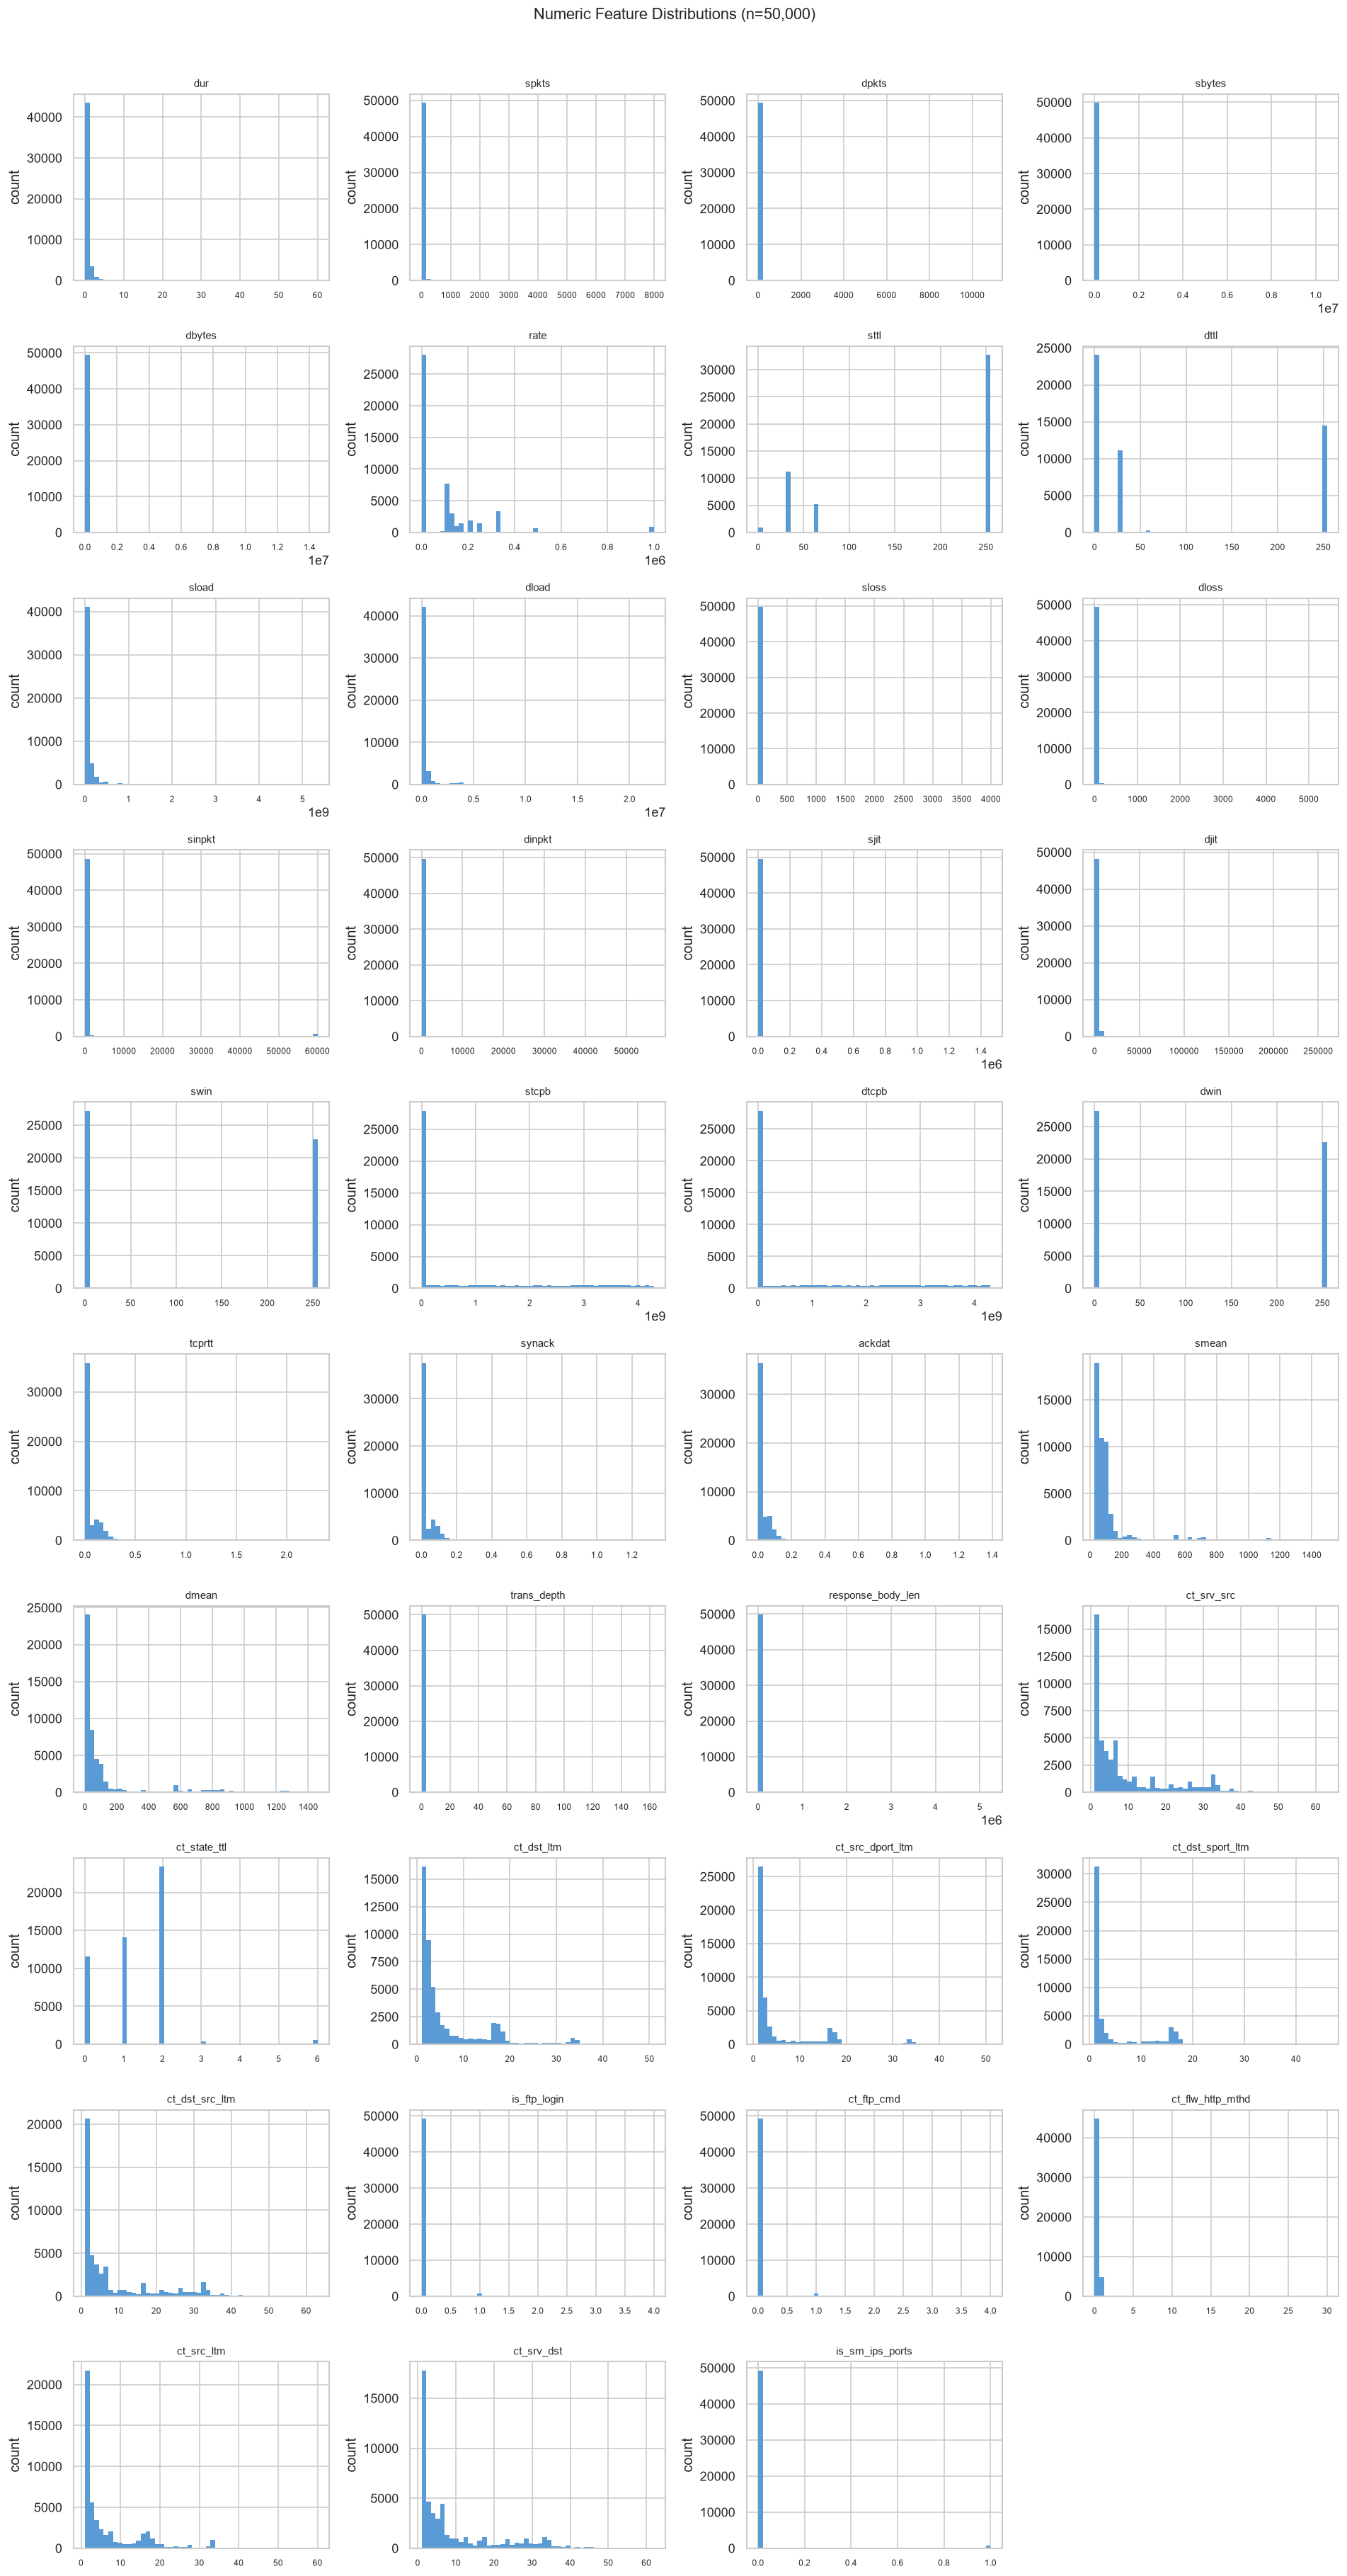

Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\numeric_distributions_train.png


In [11]:
fig_path = FIGURES_DIR / 'numeric_distributions_train.png'
plot_numeric_distributions(
    train_df, NUMERIC_FEATURE_COLS, fig_path, sample_n=50_000
)
from IPython.display import Image
display(Image(filename=str(fig_path)))
print(f'Saved: {fig_path}')

**Observations:**
- Byte-count features (`sbytes`, `dbytes`) and load features (`sload`, `dload`) are heavily
  right-skewed with long tails — maximum values are orders of magnitude above the median.
- Several features (`stcpb`, `dtcpb`) have near-uniform or multi-modal distributions,
  reflecting different protocol behaviours.
- Connection counters (`ct_srv_src`, `ct_dst_ltm`, etc.) are concentrated near zero with
  sporadic large values.
- These skewed distributions motivate the use of a `StandardScaler` in preprocessing,
  and suggest that tree-based models (Random Forest) may be more robust than Logistic
  Regression to un-normalised magnitudes.

## 7. Categorical feature frequencies

Three columns are categorical: `proto` (transport protocol), `service` (application
service), and `state` (connection state).  High cardinality in `proto` means one-hot
encoding will produce many columns — the actual count will be reviewed in Phase 3.

In [12]:
for col in CAT_FEATURE_COLS:
    s = categorical_summary(train_df, col)
    print(f"\n--- '{col}' ({s['value'].nunique()} unique values in train) ---")
    print(s.head(10).to_string(index=False))


--- 'proto' (133 unique values in train) ---
 value  count   pct
   tcp  79946 45.59
   udp  63283 36.09
  unas  12084  6.89
   arp   2859  1.63
  ospf   2595  1.48
  sctp   1150  0.66
   any    300  0.17
   gre    225  0.13
sun-nd    201  0.11
 swipe    201  0.11

--- 'service' (13 unique values in train) ---
   value  count   pct
       -  94168 53.71
     dns  47294 26.97
    http  18724 10.68
    smtp   5058  2.88
ftp-data   3995  2.28
     ftp   3428  1.96
     ssh   1302  0.74
    pop3   1105  0.63
    dhcp     94  0.05
    snmp     80  0.05

--- 'state' (9 unique values in train) ---
value  count   pct
  INT  82275 46.92
  FIN  77825 44.38
  CON  13152  7.50
  REQ   1991  1.14
  RST     83  0.05
  ECO     12  0.01
  PAR      1  0.00
  URN      1  0.00
   no      1  0.00


INFO: Saved categorical frequencies chart: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\categorical_frequencies_train.png


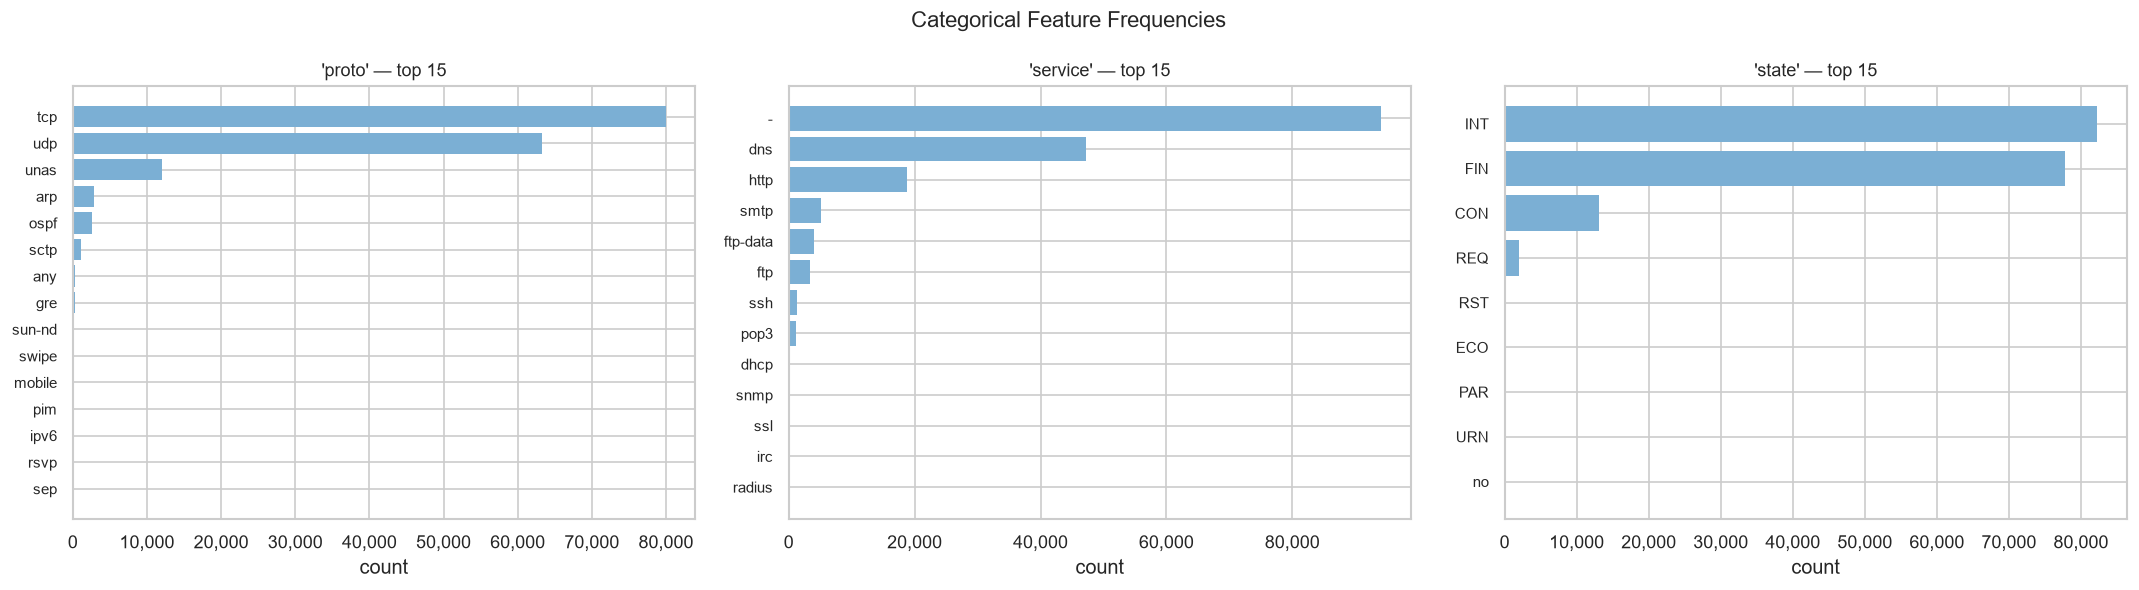

Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\categorical_frequencies_train.png


In [13]:
fig_path = FIGURES_DIR / 'categorical_frequencies_train.png'
plot_categorical_frequencies(train_df, CAT_FEATURE_COLS, fig_path, top_n=15)
display(Image(filename=str(fig_path)))
print(f'Saved: {fig_path}')

**Observations:**
- `proto` has many distinct values but `tcp` and `udp` dominate. Rare protocols may be
  grouped into an "other" category during preprocessing to limit one-hot expansion.
- `service` is mostly `-` (no identified service), followed by `dns` and `http`.
- `state` is dominated by `INT` (in-progress) and `FIN` (finished), which map closely to
  TCP handshake behaviour.

## 8. Numeric feature correlation heatmap

Pearson correlation reveals linear relationships between features.
`id`, `label`, and `attack_cat` are excluded — the correlation matrix
should reflect feature-to-feature relationships only.

> **Limitation:** Pearson correlation only captures linear relationships.
> Non-linear dependencies (common in network data) will not appear here.

INFO: Saved correlation heatmap: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\correlation_heatmap_train.png


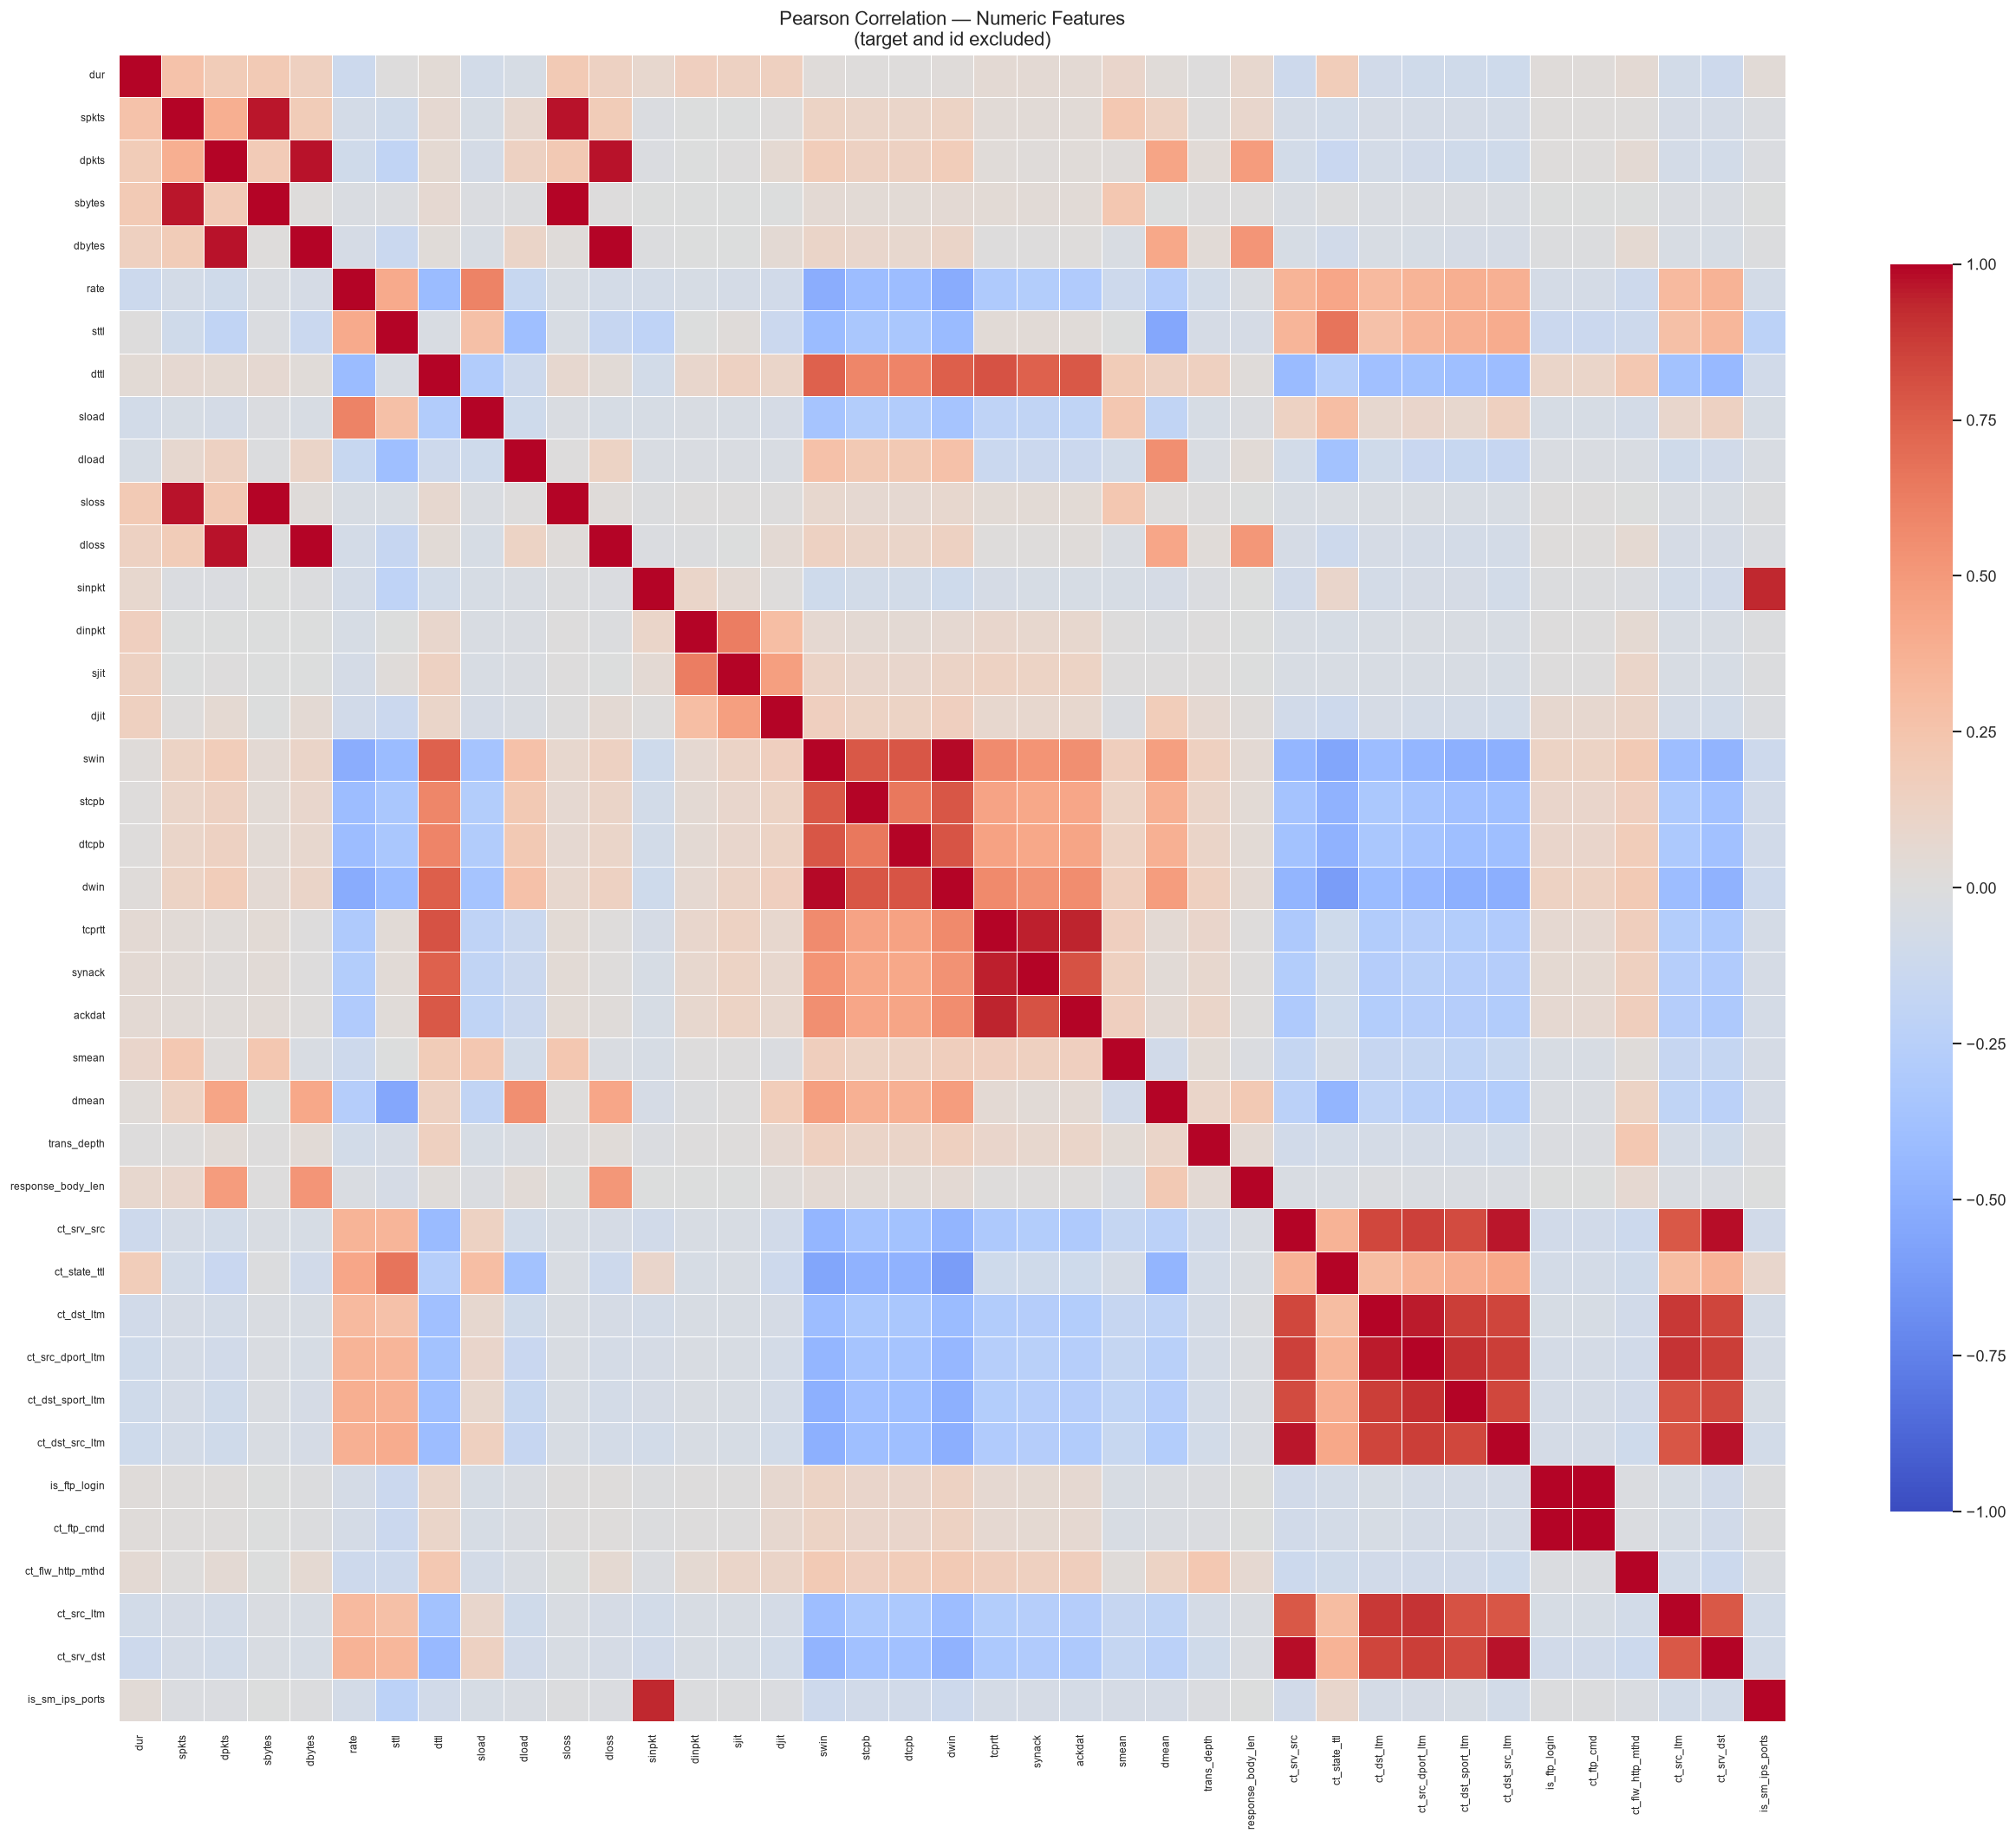

Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\correlation_heatmap_train.png


In [14]:
fig_path = FIGURES_DIR / 'correlation_heatmap_train.png'
plot_correlation_heatmap(
    train_df, NUMERIC_FEATURE_COLS, fig_path, sample_n=50_000
)
display(Image(filename=str(fig_path)))
print(f'Saved: {fig_path}')

**Observations to note for Phase 3:**
- Some byte/packet pairs (`sbytes`/`spkts`, `dbytes`/`dpkts`) are likely correlated — the
  preprocessor does not need to remove them, but it is useful to know.
- TTL-related features (`sttl`, `dttl`) may cluster differently for attacks vs normal
  traffic; this will be visible in the model's feature importance (Phase 5).
- High correlation between a subset of connection counters (`ct_*`) is expected because
  they count similar quantities over a time window.

## 9. Attack-category distribution

`attack_cat` is a **descriptive** column — it names the attack type for rows where
`label == 1`.  For normal rows (`label == 0`) it is NaN (displayed here as "Normal").

This analysis is for understanding only.  In the binary classification task,
`attack_cat` is **excluded from all model inputs** because it reveals information
directly derived from the attack outcome.

In [15]:
print('Attack categories — TRAIN split:')
train_cat_summary = attack_category_summary(train_df, 'train')
print(train_cat_summary.to_string(index=False))
print()
print('Attack categories — TEST split:')
test_cat_summary = attack_category_summary(test_df, 'test')
print(test_cat_summary.to_string(index=False))

Attack categories — TRAIN split:
    attack_cat  count   pct
        Normal  56000 31.94
       Generic  40000 22.81
      Exploits  33393 19.04
       Fuzzers  18184 10.37
           DoS  12264  6.99
Reconnaissance  10491  5.98
      Analysis   2000  1.14
      Backdoor   1746  1.00
     Shellcode   1133  0.65
         Worms    130  0.07

Attack categories — TEST split:
    attack_cat  count   pct
        Normal  37000 44.94
       Generic  18871 22.92
      Exploits  11132 13.52
       Fuzzers   6062  7.36
           DoS   4089  4.97
Reconnaissance   3496  4.25
      Analysis    677  0.82
      Backdoor    583  0.71
     Shellcode    378  0.46
         Worms     44  0.05


INFO: Saved attack category chart: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\attack_category_distribution_train.png


INFO: Saved attack category chart: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\attack_category_distribution_test.png


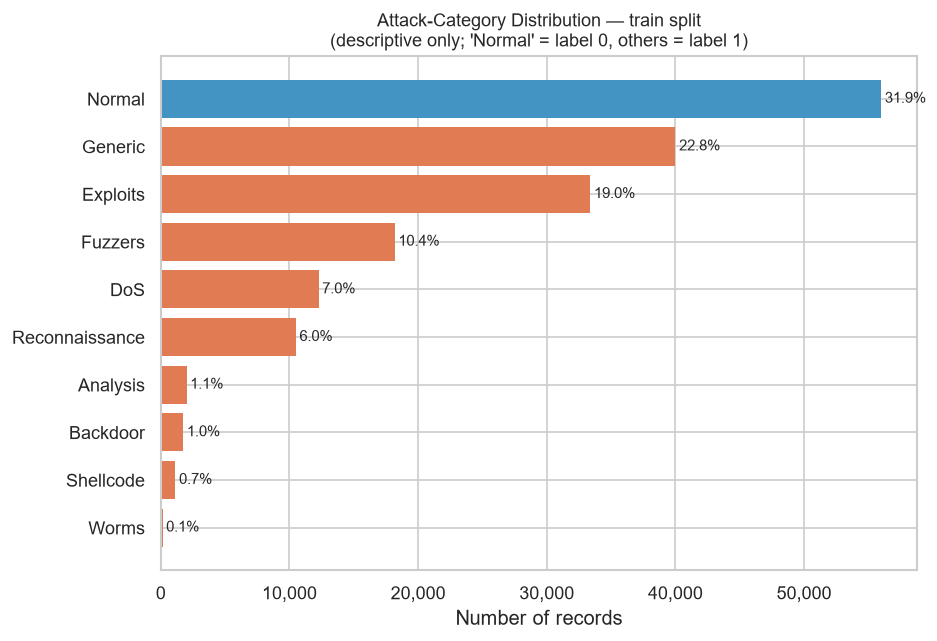

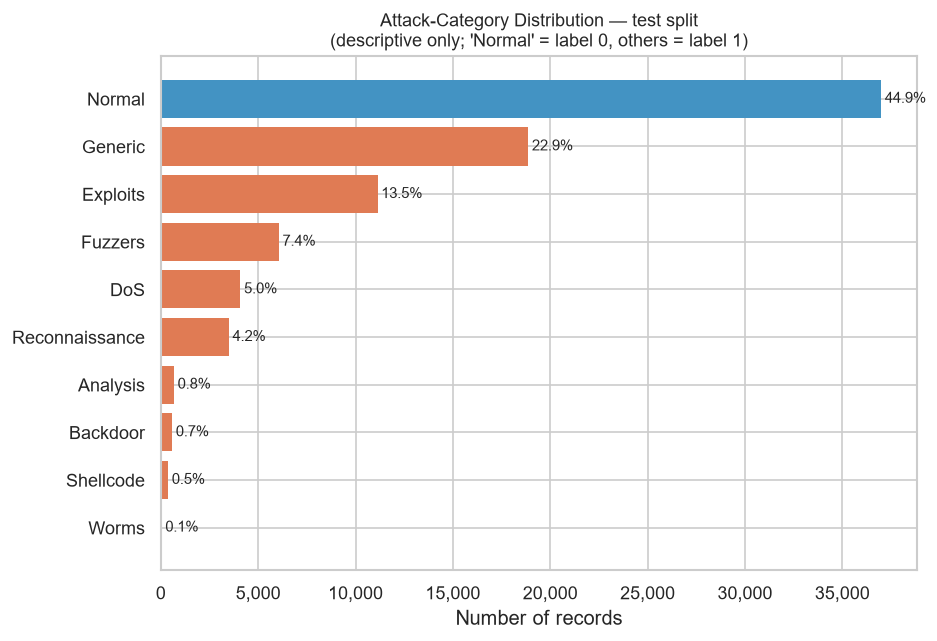

Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\attack_category_distribution_train.png
Saved: C:\Users\meema\ML_Network_Intrusion_Detection\results\figures\attack_category_distribution_test.png


In [16]:
fig_path_train = FIGURES_DIR / 'attack_category_distribution_train.png'
fig_path_test  = FIGURES_DIR / 'attack_category_distribution_test.png'

plot_attack_category_distribution(train_df, 'train', fig_path_train)
plot_attack_category_distribution(test_df,  'test',  fig_path_test)

display(Image(filename=str(fig_path_train)))
display(Image(filename=str(fig_path_test)))
print(f'Saved: {fig_path_train}')
print(f'Saved: {fig_path_test}')

**Observations:**
- Generic and Exploits attacks dominate both splits, together accounting for ~52% of all
  training records.
- Worms (130 in train, 44 in test) is the rarest attack category — a binary classifier may
  struggle with such rare sub-types even if overall F1 is high.
- The category proportions are broadly preserved between train and test splits, suggesting
  a consistent stratified sampling strategy was used in dataset construction.
- **Reminder:** `attack_cat` is for descriptive understanding only and is excluded from
  model features.

## 10. Save machine-readable EDA summary

A consolidated JSON summary is written to `results/metrics/eda_summary.json`.
It captures all key findings from this notebook in a form that can be referenced
by the project report.

In [17]:
eda_summary = {
    "generated_by": "notebooks/01_exploratory_data_analysis.ipynb",
    "dataset": "UNSW-NB15 (official predefined split)",
    "train": {
        "rows":    train_overview["rows"],
        "columns": train_overview["columns"],
        "numeric_feature_count":     len(NUMERIC_FEATURE_COLS),
        "categorical_feature_count": len(CAT_FEATURE_COLS),
        "class_distribution":  train_dist,
        "duplicate_rows":       train_dups["duplicate_rows"],
        "duplicate_ids":        train_dups["duplicate_ids"],
        "missing_total":        train_overview["missing_total"],
        "attack_categories":    train_cat_summary.to_dict(orient="records"),
    },
    "test": {
        "rows":    test_overview["rows"],
        "columns": test_overview["columns"],
        "class_distribution":  test_dist,
        "duplicate_rows":       test_dups["duplicate_rows"],
        "duplicate_ids":        test_dups["duplicate_ids"],
        "missing_total":        test_overview["missing_total"],
        "attack_categories":    test_cat_summary.to_dict(orient="records"),
    },
    "id_column_analysis": id_info,
    "columns_excluded_from_features": {
        "label":      "Binary target — not a feature.",
        "attack_cat": "Reveals attack category; leaks outcome information.",
        "id":         "Row identifier; no predictive signal; overlaps between splits.",
    },
    "figures": {
        "class_distribution":           "results/figures/class_distribution_both_splits.png",
        "numeric_distributions":        "results/figures/numeric_distributions_train.png",
        "categorical_frequencies":      "results/figures/categorical_frequencies_train.png",
        "correlation_heatmap":          "results/figures/correlation_heatmap_train.png",
        "attack_cat_train":             "results/figures/attack_category_distribution_train.png",
        "attack_cat_test":              "results/figures/attack_category_distribution_test.png",
    },
}

summary_path = METRICS_DIR / 'eda_summary.json'
save_eda_summary(eda_summary, summary_path)
print(f'EDA summary saved to: {summary_path}')

INFO: Saved EDA summary: C:\Users\meema\ML_Network_Intrusion_Detection\results\metrics\eda_summary.json


EDA summary saved to: C:\Users\meema\ML_Network_Intrusion_Detection\results\metrics\eda_summary.json


## 11. EDA findings summary and Phase 3 notes

| Finding | Implication for Phase 3 |
|---|---|
| **No missing values** | No imputer strictly required; include `SimpleImputer` for robustness |
| **No duplicate rows or IDs** | Dataset is clean; no deduplication needed |
| **Attack-heavy class balance** (68% train, 55% test) | Report per-class precision/recall, not just accuracy |
| **`id` overlaps between splits** | Exclude `id` from all model features |
| **Heavily skewed numeric features** | `StandardScaler` recommended; tree models are scale-invariant |
| **`proto` has many categories** | Investigate `OneHotEncoder(max_categories=…)` or frequency grouping |
| **`attack_cat` reveals attack type** | Exclude from all binary model inputs |

**No preprocessing, imputation, or model fitting was performed in this notebook.**  
All analysis is read-only on the raw loaded DataFrames.